# Git과 Docker 준비

**이 노트북에서 할 일**

1. 명령 git·uv·docker를 찾고, 찾은 명령이 버전 질문에 응답하는지 확인합니다.
2. 임시 폴더를 Git 저장소로 만들고, 4절의 `hello.py`를 저장·기록·수정하며 상태 출력이 바뀌는 것을 봅니다.
3. Docker의 클라이언트와 서버를 따로 확인하고, 여섯 가지 준비 상태를 한곳에 모읍니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 노트북이 임시 폴더에 저장소를 직접 만듭니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

2절에서 설치한 Git이 필요합니다. 노트북은 Docker가 없어도 끝까지 실행되고, 없다는 결과를 그대로 보여 줍니다.
커널은 3절에서 준비한 실습 폴더의 `.venv`를 고릅니다.

## 오늘 볼 그림

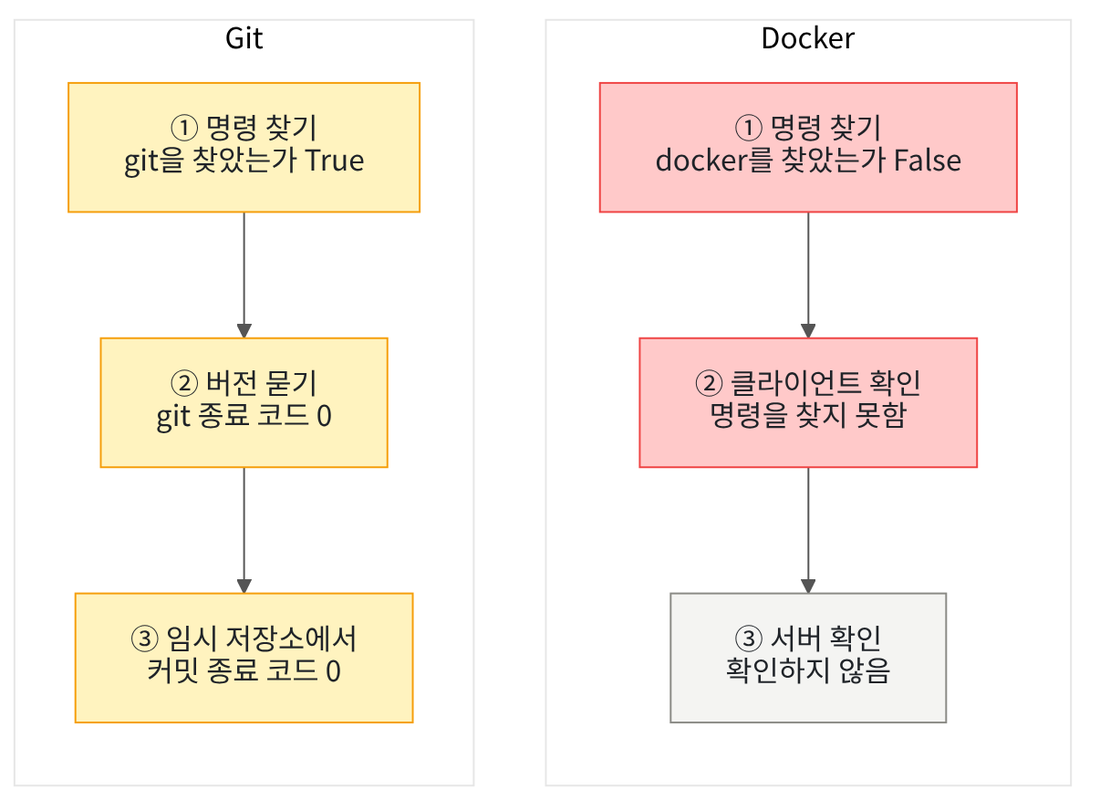

왼쪽 칸은 Git, 오른쪽 칸은 Docker이고, 두 칸 모두 위에서 아래로 읽습니다.
노란 상자는 확인을 통과한 결과이고, 빨간 상자는 준비되지 않은 결과입니다. 회색 상자는 확인하지 않은 단계입니다.
앞 단계를 통과해야 다음 단계를 확인합니다. 이 교재 환경에서는 Git이 세 단계를 모두 통과했고, Docker는 첫 단계에서 멈췄습니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 3절과 4절에서 쓴 기본 기능 여섯 가지를 다시 불러옵니다.
모듈 `shutil`은 명령의 위치를 찾고, 모듈 `subprocess`는 노트북 안에서 다른 프로그램을 실행합니다.
모듈 `platform`과 `sys`는 실행 중인 Python의 정보를, 모듈 `tempfile`과 경로 기능 `Path`는 임시 폴더와 경로를 다룹니다.

In [1]:
# 이 절에서 쓰는 Python 기본 기능을 불러옵니다
import platform
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

print("불러오기 완료")

불러오기 완료


**결과 읽기** — `불러오기 완료`가 보이면 다음 셀로 넘어갑니다.

## 2. 명령 찾기

3절에서 함수 `shutil.which()`로 uv 명령의 위치를 찾았습니다. 찾지 못하면 값이 없다는 뜻의 `None`을 반환합니다.
이번에는 같은 방법으로 명령 세 개 git, uv, docker를 찾습니다.

실행 전에 예상합니다. 2절에서 설치한 git과 uv는 찾을 것입니다. 명령 docker는 컴퓨터마다 다릅니다.
명령 git은 이 노트북의 뒤쪽 셀에 꼭 필요해서, 찾지 못하면 검사 줄 `assert`에서 멈춥니다.

In [2]:
# 명령 git, uv, docker가 어디 있는지 찾습니다
git_path = shutil.which("git")
uv_path = shutil.which("uv")
docker_path = shutil.which("docker")
# 위치는 사람마다 달라서 찾았는지만 출력합니다
print("git을 찾았는가:", git_path is not None)
print("uv를 찾았는가:", uv_path is not None)
print("docker를 찾았는가:", docker_path is not None)
# git을 찾지 못했다면 여기서 멈추고, 2절의 설치 표를 다시 봅니다
assert git_path is not None

git을 찾았는가: True
uv를 찾았는가: True
docker를 찾았는가: False


**결과 읽기** — git과 uv는 `True`, docker는 `False`입니다. 검사 줄에서 멈추지 않았습니다.
이 교재 환경에는 Docker가 설치되어 있지 않습니다. 셋째 줄은 Docker를 설치한 컴퓨터에서 `True`로 나올 것입니다.

위치를 찾은 것은 첫 단계일 뿐입니다. 다음 셀에서 찾은 명령이 실제로 응답하는지 봅니다.

## 3. 버전을 물어 응답 확인하기

2절에서 새 터미널에 `uv --version`을 입력해 설치를 확인했습니다. 노트북에서도 같은 질문을 git과 uv에게 합니다.
3절처럼 함수 `subprocess.run()`에 명령 목록을 넣고, 종료 코드 `returncode`를 읽습니다. 종료 코드 0은 오류 없이 끝났다는 뜻입니다.

메서드 `strip()`은 4절에서 봤듯이 출력 끝의 줄바꿈을 떼어 냅니다.

In [3]:
# git과 uv에게 버전을 물어 실제로 응답하는지 확인합니다
git_version_command = [git_path, "--version"]
git_version_run = subprocess.run(git_version_command, capture_output=True, text=True)
uv_version_command = [uv_path, "--version"]
uv_version_run = subprocess.run(uv_version_command, capture_output=True, text=True)
# 종료 코드가 0이면 응답한 것으로 봅니다
git_ready = git_version_run.returncode == 0
uv_ready = uv_version_run.returncode == 0
print("git 종료 코드:", git_version_run.returncode)
print("git 응답:", git_version_run.stdout.strip())
print("uv 종료 코드:", uv_version_run.returncode)

git 종료 코드: 0
git 응답: git version 2.34.1
uv 종료 코드: 0


**결과 읽기** — git 종료 코드는 `0`이고, 응답은 `git version 2.34.1`입니다. uv 종료 코드도 `0`입니다.
버전 번호는 이 교재 환경의 값입니다. 내 컴퓨터에서는 다른 번호가 나와도 괜찮습니다.

명령 위치를 찾았고, 버전 질문에도 응답했습니다. 이제 Git으로 실제 작업을 해 봅니다.

## 4. 임시 폴더를 Git 저장소로 만들기

저장소(repository)는 Git이 파일의 변경을 기록하는 폴더입니다. 명령 `git init`은 지금 폴더를 저장소로 만듭니다.
실제 프로젝트를 건드리지 않도록 2절처럼 임시 폴더 `workspace`에서 연습합니다.

인자 `cwd`는 명령을 실행할 폴더입니다. 노트북 폴더가 아니라 `workspace`에서 git을 실행하게 합니다.
명령 `git status --short`는 저장소에서 달라진 파일을 한 줄에 하나씩 짧게 보여 줍니다.
실행 전에 예상합니다. 아직 파일이 없으므로 상태 출력은 0줄일 것입니다.

In [4]:
# 연습용 임시 폴더를 만들고, 그 폴더에서 git init을 실행합니다
temporary_folder = tempfile.TemporaryDirectory()
workspace = Path(temporary_folder.name)
init_command = [git_path, "init"]
init_run = subprocess.run(init_command, cwd=workspace, capture_output=True, text=True)
# git init은 폴더 안에 기록용 폴더 .git을 만듭니다
git_folder = workspace / ".git"
print("git init 종료 코드:", init_run.returncode)
print(".git 폴더가 있는가:", git_folder.is_dir())
# 같은 폴더에서 짧은 상태를 보고, 출력이 몇 줄인지 셉니다
status_command = [git_path, "status", "--short"]
empty_status = subprocess.run(status_command, cwd=workspace, capture_output=True, text=True)
empty_lines = empty_status.stdout.splitlines()
print("상태 출력 줄 수:", len(empty_lines))

git init 종료 코드: 0
.git 폴더가 있는가: True
상태 출력 줄 수: 0


**결과 읽기** — git init 종료 코드는 `0`이고, `.git` 폴더가 있는지는 `True`입니다.
상태 출력 줄 수는 `0`입니다. 저장소는 생겼지만 아직 달라진 파일이 없습니다.

폴더 `.git`은 이름이 점으로 시작해서 파일 목록에서 숨겨질 수 있습니다. 이 폴더는 직접 고치지 않습니다.

## 5. hello.py를 저장하고 상태 보기

4절의 `hello.py`와 같은 네 줄을 저장소 폴더에 저장합니다. 4절처럼 큰따옴표 세 개로 여러 줄 글을 적습니다.
실행 전에 예상합니다. 새 파일이 생겼으므로 상태 출력에 `hello.py`가 나올 것입니다.

In [5]:
# 4절의 hello.py와 같은 네 줄을 저장소 폴더에 저장합니다
hello_source = """price = 3000
count = 2
total = price * count
print(f"총액: {total}원")
"""
hello_file = workspace / "hello.py"
hello_file.write_text(hello_source, encoding="utf-8")
# 앞 셀과 같은 상태 명령을 다시 실행합니다
new_status = subprocess.run(status_command, cwd=workspace, capture_output=True, text=True)
print("상태 출력:", new_status.stdout.strip())

상태 출력: ?? hello.py


**결과 읽기** — 상태 출력은 `?? hello.py`입니다. 예상대로 파일 이름이 나왔습니다.
물음표 두 개 `??`는 Git이 처음 보는 파일이라는 표시입니다. 파일을 발견했지만 아직 기록 대상은 아닙니다.

## 6. 기록할 파일로 올리기

명령 `git add 파일이름`은 그 파일을 다음 기록에 넣을 목록에 올립니다. 아직 기록을 만든 것은 아닙니다.
3절처럼 인자 `check=True`를 넣어, 명령이 실패하면 셀도 멈추게 합니다.
실행 전에 예상합니다. 상태 출력 앞의 표시가 `??`에서 다른 글자로 바뀔 것입니다.

In [6]:
# git add로 hello.py를 다음 기록에 넣을 목록에 올립니다
add_command = [git_path, "add", "hello.py"]
subprocess.run(add_command, cwd=workspace, check=True)
# 목록에 올린 뒤의 상태를 봅니다
added_status = subprocess.run(status_command, cwd=workspace, capture_output=True, text=True)
print("상태 출력:", added_status.stdout.strip())

상태 출력: A  hello.py


**결과 읽기** — 상태 출력은 `A  hello.py`입니다. 글자 `A`는 기록할 목록에 새로 올린(added) 파일이라는 표시입니다.
같은 파일인데 표시가 `??`에서 `A`로 바뀌었습니다. 이제 이 파일은 기록할 준비를 마쳤습니다.

## 7. 기록 만들기

커밋(commit)은 지금 파일의 모습을 저장소에 한 번 기록하는 일입니다. 명령은 `git commit -m "메시지"`입니다.
커밋할 때 Git은 만든 사람의 이름과 전자우편을 함께 적습니다. 이 설정이 없으면 컴퓨터에 따라 커밋이 실패합니다.

그래서 옵션 `-c`로 이번 명령에만 쓸 이름과 전자우편을 넣습니다. 내 컴퓨터의 Git 설정은 바뀌지 않습니다.
옵션 `--quiet`는 안내 메시지를 줄입니다. 실행 전에 예상합니다. 기록한 뒤에는 달라진 파일이 없으니 상태 출력이 0줄일 것입니다.

In [7]:
# 이번 명령에만 쓸 이름과 전자우편을 -c로 넣고 커밋을 만듭니다
name_setting = "user.name=Ch1 Student"
email_setting = "user.email=student@example.com"
commit_command = [
    git_path, "-c", name_setting, "-c", email_setting,
    "commit", "--quiet", "-m", "hello.py 첫 기록",
]
commit_run = subprocess.run(commit_command, cwd=workspace, capture_output=True, text=True)
# 기록한 뒤의 상태가 몇 줄인지 셉니다
committed_status = subprocess.run(status_command, cwd=workspace, capture_output=True, text=True)
committed_lines = committed_status.stdout.splitlines()
print("커밋 종료 코드:", commit_run.returncode)
print("상태 출력 줄 수:", len(committed_lines))

커밋 종료 코드: 0
상태 출력 줄 수: 0


**결과 읽기** — 커밋 종료 코드는 `0`이고, 상태 출력 줄 수는 `0`입니다.
파일은 그대로 있지만, 지금 파일이 방금 만든 기록과 같아서 표시할 것이 없습니다.

기록마다 붙는 번호(커밋 해시)는 실행할 때마다 달라서 출력하지 않았습니다.

## 실험: 기록한 뒤 수량을 3으로 바꾸기

4절의 값 바꿔 보기처럼 `hello.py`의 수량만 2에서 3으로 바꿔 저장합니다. 메서드 `replace()`는 4절에서 썼습니다.
실행 전에 예상합니다. 기록과 파일이 달라졌으므로 상태 출력에 `hello.py`가 다시 나올 것입니다. 표시는 `??`나 `A`가 아닐 것입니다.

In [8]:
# 4절의 값 바꿔 보기처럼 수량만 3으로 바꿔 같은 파일에 저장합니다
changed_source = hello_source.replace("count = 2", "count = 3")
hello_file.write_text(changed_source, encoding="utf-8")
# 바꾼 뒤의 상태를 봅니다
changed_status = subprocess.run(status_command, cwd=workspace, capture_output=True, text=True)
print("상태 출력:", changed_status.stdout.strip())

상태 출력: M hello.py


**결과 읽기** — 상태 출력은 `M hello.py`입니다. 글자 `M`은 기록한 뒤에 내용이 바뀐(modified) 파일이라는 표시입니다.
노트북은 `strip()`으로 앞 빈칸을 떼어 출력에는 보이지 않습니다. 원래 출력의 빈칸은 교재 환경의 기기 셸에서 따로 확인했습니다.

어느 줄이 바뀌었는지는 상태 출력에 없습니다. 다음 셀에서 기록과 지금 파일을 줄 단위로 비교합니다.

## 기록과 지금 파일 비교하기

명령 `git diff`는 기록할 목록과 지금 파일을 비교해 다른 줄을 보여 줍니다.
커밋한 뒤 `git add`를 하지 않아 목록이 마지막 기록과 같으므로, 이번에는 기록과 파일을 비교한 결과와 같습니다.
목록 쪽에만 있던 줄은 앞에 `-`가, 지금 파일에만 있는 줄은 앞에 `+`가 붙습니다.

출력에는 파일 이름을 적은 `---`와 `+++` 줄도 섞여 있습니다. 4절에서 디버거 출력을 고를 때처럼 반복문과 조건으로 그 줄을 뺍니다.
메서드 `startswith()`는 글이 괄호 속 글자로 시작하면 `True`를 만듭니다. 연산자 `or`는 둘 중 하나라도 `True`이면 `True`를 만듭니다.

In [9]:
# 기록할 목록(지금은 마지막 기록과 같음)과 지금 파일을 비교하고, 바뀐 줄만 골라 출력합니다
diff_command = [git_path, "diff"]
diff_run = subprocess.run(diff_command, cwd=workspace, capture_output=True, text=True)
diff_lines = diff_run.stdout.splitlines()
for line in diff_lines:
    # ---와 +++로 시작하는 줄은 파일 이름을 적은 줄이라 뺍니다
    is_file_name = line.startswith("---") or line.startswith("+++")
    is_changed = line.startswith("-") or line.startswith("+")
    if is_changed and not is_file_name:
        print(line)

-count = 2
+count = 3


**결과 읽기** — 두 줄이 나왔습니다. 첫 줄 `-count = 2`는 기록에 있던 줄이고, 둘째 줄 `+count = 3`은 지금 파일의 줄입니다.
네 줄 중 수량 줄 하나만 바뀌었다는 것을 Git이 찾아 줬습니다. 1절부터 해 온 「예상과 출력 비교」를 이번에는 Git이 목록(지금은 마지막 기록과 같음)과 파일 사이에서 했습니다.

## 값 바꿔 보기: 수량을 다시 2로

이번에는 수량을 다시 2로 되돌려 저장합니다. 파일을 한 번 더 저장했으니 저장한 시각은 기록 때와 다릅니다.
실행 전에 예상합니다. 저장 시각이 아니라 내용을 Git이 비교한다면, 기록과 내용이 같아져 상태 출력이 0줄일 것입니다.

In [10]:
# 처음 기록한 네 줄 글로 다시 저장하고 상태를 봅니다
hello_file.write_text(hello_source, encoding="utf-8")
restored_status = subprocess.run(status_command, cwd=workspace, capture_output=True, text=True)
restored_lines = restored_status.stdout.splitlines()
print("상태 출력 줄 수:", len(restored_lines))

상태 출력 줄 수: 0


**결과 읽기** — 상태 출력 줄 수는 `0`입니다. 파일을 다시 저장했지만 내용이 기록과 같아서 바뀐 파일로 표시되지 않았습니다.
이번 실행에서 Git은 파일 내용을 기준으로 달라졌는지 판단했습니다.

## 8. Docker 클라이언트 확인하기

Docker 도구는 프로그램과 실행 조건을 묶어, 다른 컴퓨터에서도 같은 조건으로 실행하게 돕습니다. 두 부분으로 나뉩니다.
우리가 입력하는 `docker` 명령은 클라이언트(client)입니다. 요청을 받아 실제 일을 하는 쪽은 서버, 곧 데몬(daemon)입니다.

앞의 셀에서 docker 명령을 찾지 못했으면 버전을 물을 수 없습니다. 여러 줄 `if/else`로 두 경우를 나눕니다.
실행 전에 예상합니다. 이 교재 환경은 docker를 찾지 못했으므로 `if` 아래 줄이 실행될 것입니다.

In [11]:
# docker 명령을 찾았을 때만 클라이언트에게 버전을 묻습니다
docker_client_ready = False
if docker_path is None:
    print("Docker 클라이언트: 명령을 찾지 못함")
else:
    client_command = [docker_path, "--version"]
    client_run = subprocess.run(client_command, capture_output=True, text=True)
    docker_client_ready = client_run.returncode == 0
    print("Docker 클라이언트 종료 코드:", client_run.returncode)
    print("Docker 클라이언트 응답:", client_run.stdout.strip())
print("Docker 클라이언트가 준비됐는가:", docker_client_ready)

Docker 클라이언트: 명령을 찾지 못함
Docker 클라이언트가 준비됐는가: False


**결과 읽기** — `Docker 클라이언트: 명령을 찾지 못함`이 나왔고, 준비됐는지는 `False`입니다.
명령을 찾지 못해서 `else` 아래 줄은 이번에 실행하지 않았습니다. 그 줄은 Docker를 설치한 컴퓨터에서 실행되어 종료 코드와 버전을 출력할 것입니다.

## 9. Docker 서버 확인하기

클라이언트가 응답해도 서버가 실행 중인지는 따로 확인해야 합니다. 명령 `docker version`은 클라이언트 정보와 서버 정보를 함께 보여 줍니다.
옵션 `--format` 뒤의 글은 그중 서버 버전만 고르라는 뜻입니다. 코드는 종료 코드가 0이고 버전 글이 비어 있지 않을 때만 서버가 응답했다고 봅니다.

클라이언트가 준비되지 않았다면 서버에게 물을 방법이 없습니다. 실행 전에 예상합니다. 이번에는 확인하지 않는다는 줄이 나올 것입니다.

In [12]:
# 클라이언트가 준비됐을 때만 서버(데몬)에게 버전을 묻습니다
docker_server_ready = False
if docker_client_ready:
    server_command = [docker_path, "version", "--format", "{{.Server.Version}}"]
    server_run = subprocess.run(server_command, capture_output=True, text=True)
    server_version = server_run.stdout.strip()
    # 종료 코드가 0이고 버전 글이 비어 있지 않아야 서버가 응답한 것입니다
    docker_server_ready = server_run.returncode == 0 and server_version != ""
    print("Docker 서버 종료 코드:", server_run.returncode)
else:
    print("Docker 서버: 클라이언트가 준비되지 않아 확인하지 않음")
print("Docker 서버가 준비됐는가:", docker_server_ready)

Docker 서버: 클라이언트가 준비되지 않아 확인하지 않음
Docker 서버가 준비됐는가: False


**결과 읽기** — `Docker 서버: 클라이언트가 준비되지 않아 확인하지 않음`이 나왔고, 준비됐는지는 `False`입니다.
서버에게 버전을 묻는 `if` 아래 줄은 이번에 실행하지 않았습니다. 설치한 컴퓨터에서 서버 칸이 `False`이면 Docker Desktop 앱이 켜져 있는지 봅니다. 앱이 꺼진 상태의 출력은 이번에 실행하지 않았습니다.

## 10. 여섯 가지 준비 상태 모으기

지금까지 확인한 값과 3절에서 본 Python 확인을 한곳에 모읍니다. 여섯 줄은 서로 다른 질문의 답입니다.
값 `sys.prefix`와 `sys.base_prefix`가 다르면 커널이 가상환경 안에서 실행 중입니다. 3절에서 쓴 비교입니다.

이 목록은 다음 학습 전에 보완할 도구를 고르는 자가 점검입니다. 성적이 아닙니다.

In [13]:
# Python 버전과 가상환경 여부를 3절과 같은 방법으로 다시 확인합니다
python_version = platform.python_version()
is_python_312 = python_version.startswith("3.12")
kernel_in_venv = sys.prefix != sys.base_prefix
# 여섯 가지 준비 상태를 한곳에 출력합니다
print("Python 3.12:", is_python_312)
print("uv 응답:", uv_ready)
print("커널이 가상환경 안:", kernel_in_venv)
print("Git 응답:", git_ready)
print("Docker 클라이언트:", docker_client_ready)
print("Docker 서버:", docker_server_ready)

Python 3.12: True
uv 응답: True
커널이 가상환경 안: True
Git 응답: True
Docker 클라이언트: False
Docker 서버: False


**결과 읽기** — 위의 네 줄 Python 3.12, uv 응답, 가상환경, Git 응답은 모두 `True`입니다. 아래 두 줄 Docker 클라이언트와 서버는 `False`입니다.
이 교재 환경은 Ch 2의 Python 학습을 시작할 수 있습니다. 뒤쪽의 Docker 실습 전에는 설치부터 하고 서버까지 다시 확인해야 합니다.

## 11. 임시 폴더 정리하기

연습이 끝났으므로 2절처럼 `cleanup()`으로 임시 폴더를 지웁니다. 안에 만든 저장소와 `hello.py`도 함께 지워집니다.
실습 폴더의 `hello.py`는 이 임시 폴더 밖에 있으므로 지워지지 않습니다.

In [14]:
# 연습용 임시 폴더와 그 안의 Git 저장소를 함께 지웁니다
temporary_folder.cleanup()
print("임시 폴더가 남아 있는가:", workspace.is_dir())

임시 폴더가 남아 있는가: False


**결과 읽기** — `False`입니다. 임시 폴더와 그 안의 저장소가 지워졌습니다.

## 정리

- 명령을 찾는 것, 버전 질문에 응답하는 것, 실제 작업이 되는 것은 따로 확인했습니다. Git 확인은 세 단계를 모두 통과했습니다.
- Git 상태 출력은 `??` → `A` → 0줄 → `M` → 0줄로 바뀌었습니다. 명령 `git diff`는 바뀐 줄 `-count = 2`와 `+count = 3`을 보여 줬습니다.
- 이 교재 환경에서 docker는 명령을 찾지 못해 클라이언트와 서버 모두 `False`였습니다.

Docker 설치 컴퓨터의 클라이언트·서버 출력은 이번에 실행하지 않았습니다. 교재 본문의 설치 조건 표를 보고 내 컴퓨터에서 확인합니다.
다음 절 6절 실습에서는 1~5절의 확인을 한 점검표로 모아 새 연습 폴더를 점검합니다.